In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression


In [2]:
from sklearn.model_selection import train_test_split


df = pd.read_csv('internship_candidates_final_numeric.csv')

X = df[['Experience', 'Grade', 'EnglishLevel', 'Age', 'EntryTestScore']]
y = df['Accepted']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

df.head()

,Experience,Grade,EnglishLevel,Age,EntryTestScore,Accepted
0,3,8.2,1,25,823,0
1,4,11.6,1,26,574,0
2,2,11.8,3,23,912,1
3,4,7.7,2,28,343,0
4,4,7.8,2,24,316,0


In [3]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## Оцінка якості моделі

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Матриця помилок:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
Матриця помилок:
 [[50  0]
 [ 0 10]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        10

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



## Графік імовірності прийняття
Змінюємо рівень англійської та результат вступного тесту. Інші ознаки фіксуємо на медіанних значеннях із навчальної вибірки.

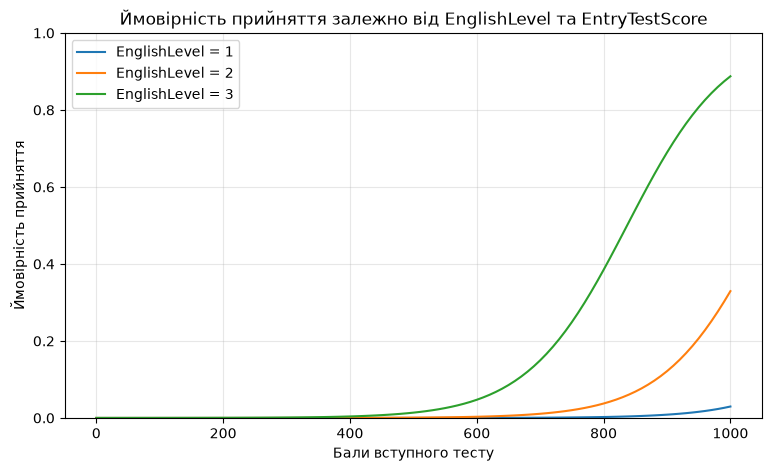

In [ ]:
english_levels = sorted(df["EnglishLevel"].unique())
scores = np.linspace(0, 1000, 101)

plt.figure(figsize=(9, 5))
for level in english_levels:
    candidates = pd.DataFrame({ # тут ми створюємо DataFrame для кандидатів з різними 
                            #    рівнями англійської мови та балами вступного тесту
        "Experience": [X_train["Experience"].median()] * len(scores),
        "Grade": [X_train["Grade"].median()] * len(scores),
        "EnglishLevel": [level] * len(scores),
        "Age": [X_train["Age"].median()] * len(scores),
        "EntryTestScore": scores
    })
    probabilities = model.predict_proba(candidates)[:, 1]
    plt.plot(scores, probabilities, label=f"EnglishLevel = {level}")

plt.xlabel("Бали вступного тесту")
plt.ylabel("Ймовірність прийняття")
plt.title("Ймовірність прийняття залежно від EnglishLevel та EntryTestScore")
plt.ylim(0, 1) #це обмеження по осі У
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Приклад прогнозу для нового кандидата

In [ ]:
new_candidate = pd.DataFrame([{
    "Experience": 2, "Grade": 9.5, "EnglishLevel": 3, "Age": 22, "EntryTestScore": 800
}])
print("Прогноз (1 — прийнято, 0 — ні):", model.predict(new_candidate)[0])
print("Ймовірність прийняття:", round(model.predict_proba(new_candidate)[0, 1] * 100, 1), "%")

Прогноз (1 — прийнято, 0 — ні): 1
Ймовірність прийняття: 70.4 %


## Додаткове завдання: назви рівнів англійської

In [15]:
english_names = {1: "Elementary", 2: "Pre-Intermediate", 3: "Intermediate"}
df_text = df.copy()
df_text["EnglishLevel"] = df_text["EnglishLevel"].map(english_names)
df_text.to_csv('internship_candidates_final_text_task2.csv', index=False)
df_text.head(10)

,Experience,Grade,EnglishLevel,Age,EntryTestScore,Accepted
0,3,8.2,Elementary,25,823,0
1,4,11.6,Elementary,26,574,0
2,2,11.8,Intermediate,23,912,1
3,4,7.7,Pre-Intermediate,28,343,0
4,4,7.8,Pre-Intermediate,24,316,0
5,1,8.9,Intermediate,18,629,0
6,2,8.7,Elementary,22,868,0
7,2,12.0,Intermediate,22,796,1
8,2,7.1,Pre-Intermediate,27,311,0
9,4,6.1,Elementary,21,617,0
